<a href="https://colab.research.google.com/github/AnjanaVP231/ML/blob/main/lab5GMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 10 records:
   Record_ID  Feature_1  Feature_2
0          1     27.955     43.791
1          2     25.671     36.404
2          3     20.564     37.704
3          4     26.570     39.699
4          5     27.773     41.462
5          6     19.087     34.235
6          7     22.674     37.352
7          8     24.669     36.034
8          9     28.950     26.449
9         10     34.325     22.493

Dataset shape: (450, 3)

Column names: ['Record_ID', 'Feature_1', 'Feature_2']

Descriptive statistics:
        Record_ID   Feature_1   Feature_2
count  450.000000  450.000000  450.000000
mean   225.500000   26.209673   32.714913
std    130.048068    5.267977    6.495383
min      1.000000   16.274000   18.980000
25%    113.250000   20.771500   25.136500
50%    225.500000   26.837500   34.913000
75%    337.750000   30.770000   37.783250
max    450.000000   37.428000   44.637000

Features used for clustering: ['Feature_1', 'Feature_2']


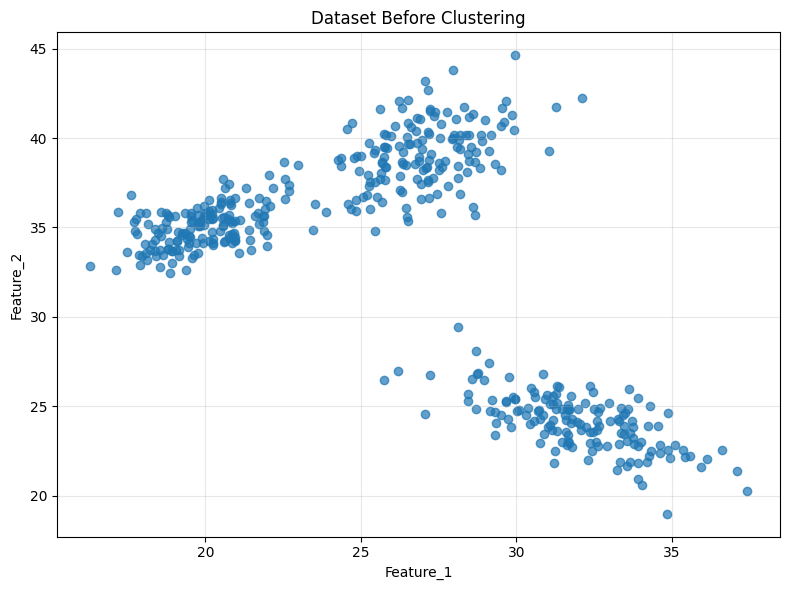


GMM cluster assignments:
 Feature_1  Feature_2  GMM_Cluster
    27.955     43.791            1
    25.671     36.404            1
    20.564     37.704            2
    26.570     39.699            1
    27.773     41.462            1
    19.087     34.235            2
    22.674     37.352            2
    24.669     36.034            1
    28.950     26.449            0
    34.325     22.493            0
    30.607     25.498            0
    25.440     34.826            1
    28.761     26.886            0
    19.559     35.406            2
    24.350     38.414            1
    21.706     35.805            2
    34.878     24.603            0
    31.641     22.848            0
    29.502     40.669            1
    26.956     39.376            1
    30.449     24.021            0
    28.710     28.082            0
    20.833     36.260            2
    31.460     22.972            0
    33.031     24.199            0
    34.571     23.894            0
    31.559     24.491        

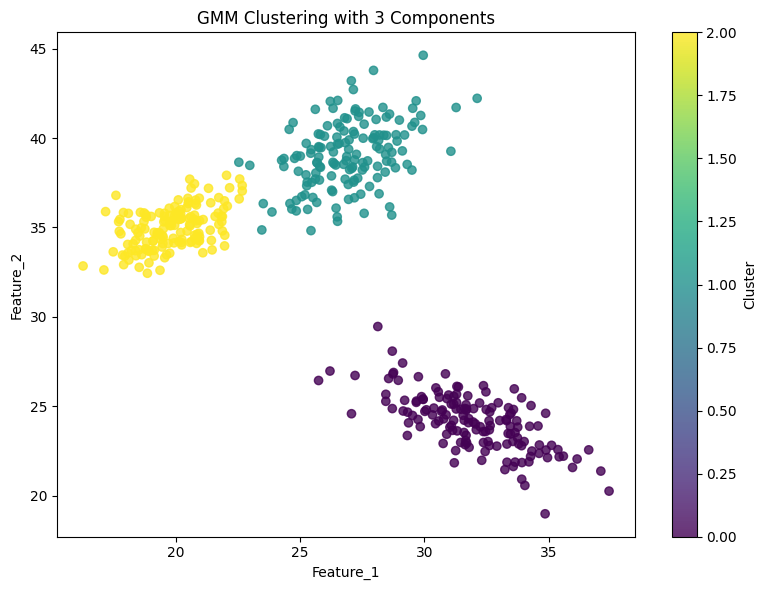


Membership probabilities for the first 10 observations:
 Record_ID  Component_1  Component_2  Component_3  Predicted_Cluster
         1          0.0       1.0000       0.0000                  1
         2          0.0       0.9997       0.0003                  1
         3          0.0       0.0030       0.9970                  2
         4          0.0       1.0000       0.0000                  1
         5          0.0       1.0000       0.0000                  1
         6          0.0       0.0000       1.0000                  2
         7          0.0       0.1947       0.8053                  2
         8          0.0       0.9881       0.0119                  1
         9          1.0       0.0000       0.0000                  0
        10          1.0       0.0000       0.0000                  0


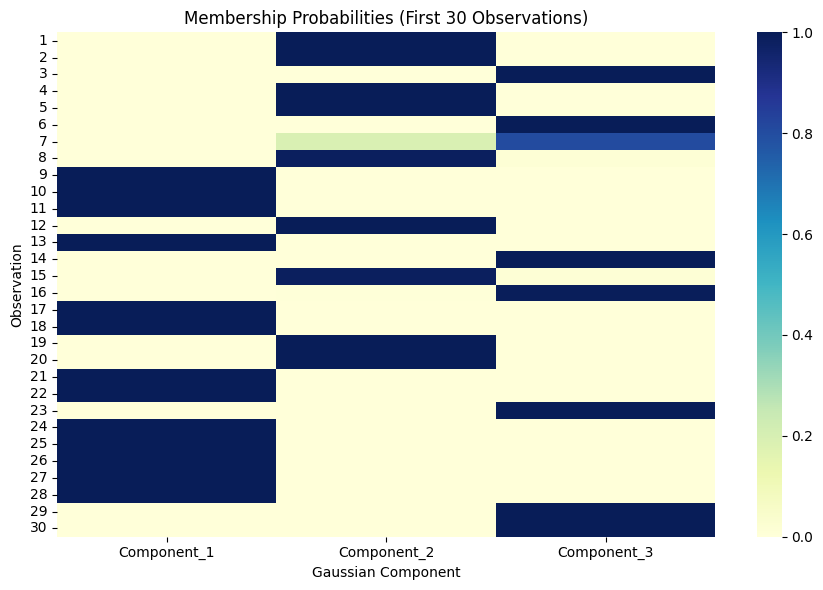


10 observations with the lowest maximum membership probabilities:
 Record_ID  Feature_1  Feature_2  Maximum_Membership_Probability
       403     22.539     38.651                          0.5149
       289     23.521     36.338                          0.6217
       200     23.463     34.863                          0.6888
        75     22.979     38.476                          0.6896
       437     22.573     37.711                          0.7837
         7     22.674     37.352                          0.8053
       152     23.871     35.869                          0.8433
       207     22.676     37.045                          0.8434
       286     22.044     37.919                          0.9079
        50     22.553     36.600                          0.9105


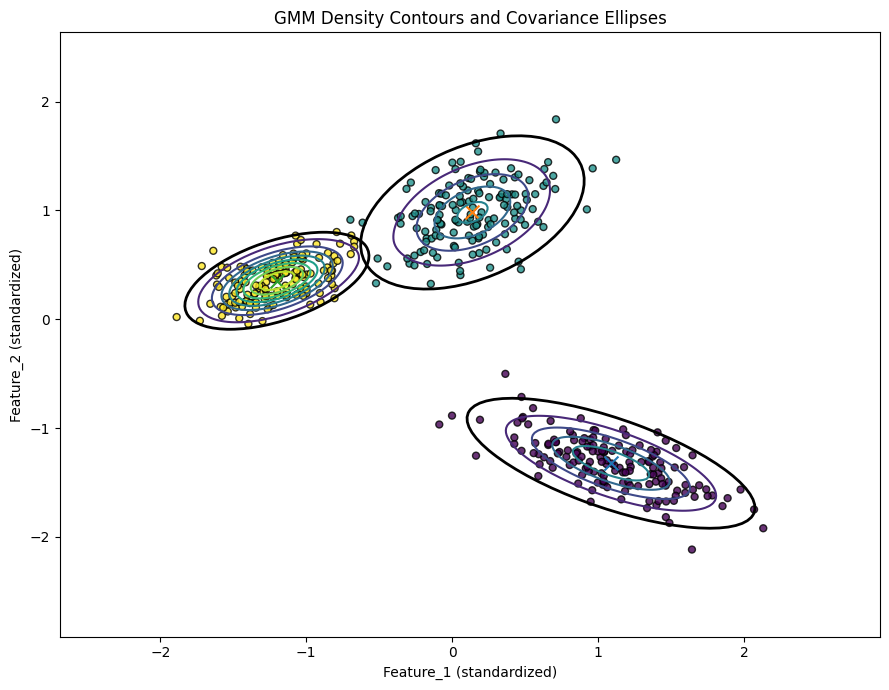

Maximum iterations:   1 | Converged: False | Iterations performed: 1 | Log-likelihood: -510.1492
Maximum iterations:   2 | Converged: False | Iterations performed: 2 | Log-likelihood: -510.0164
Maximum iterations:   5 | Converged: False | Iterations performed: 5 | Log-likelihood: -509.9737
Maximum iterations:  10 | Converged: True | Iterations performed: 6 | Log-likelihood: -509.9731
Maximum iterations:  20 | Converged: True | Iterations performed: 6 | Log-likelihood: -509.9731
Maximum iterations:  50 | Converged: True | Iterations performed: 6 | Log-likelihood: -509.9731
Maximum iterations: 100 | Converged: True | Iterations performed: 6 | Log-likelihood: -509.9731


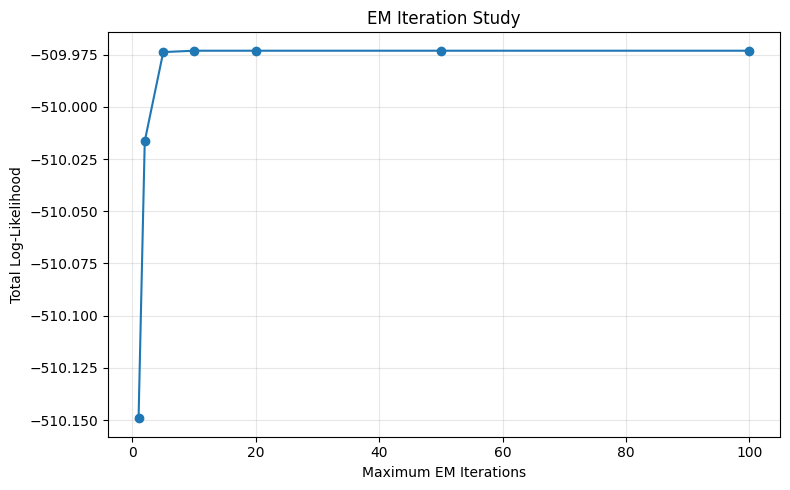


AIC and BIC comparison:
 Components      AIC      BIC
          1 2377.750 2398.296
          2 1248.851 1294.053
          3 1053.969 1123.826
          4 1066.436 1160.949
          5 1075.167 1194.335
          6 1087.079 1230.903
          7 1094.960 1263.439
          8 1101.070 1294.204

Preferred component count according to AIC: 3
Preferred component count according to BIC: 3


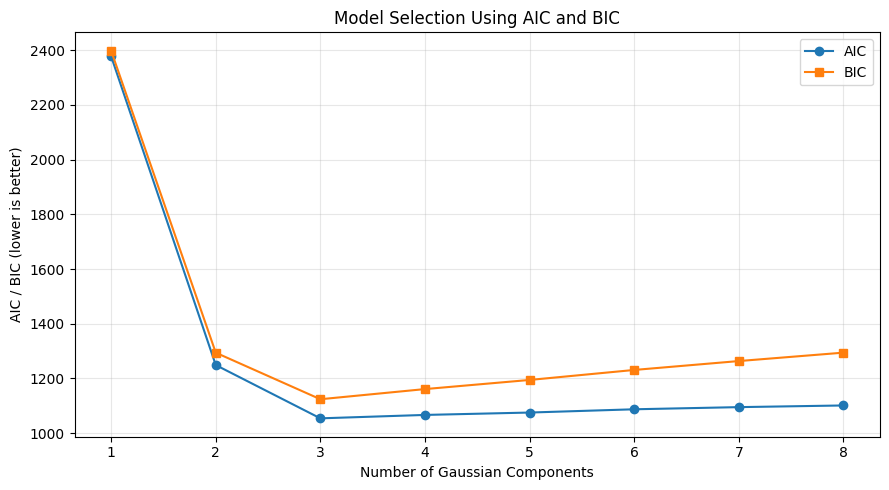


Number of clusters used for comparison: 3

Silhouette Scores:
GMM:     0.7104
K-Means: 0.7127


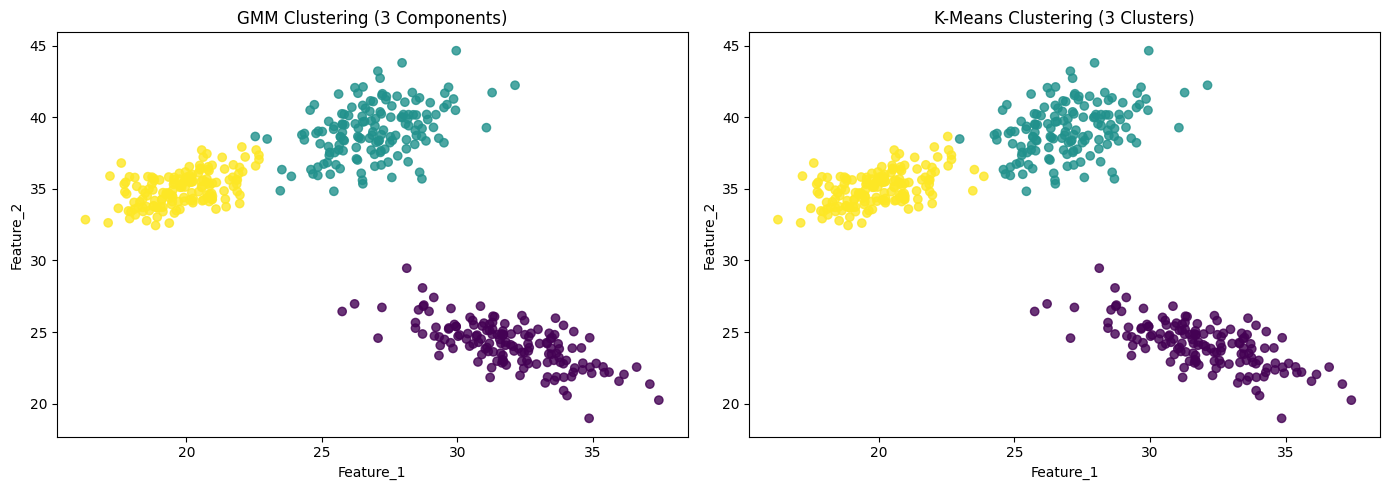


Predictions for three new observations:
 Feature_1  Feature_2  Predicted_Component  Component_1_Probability  Component_2_Probability  Component_3_Probability  Maximum_Probability
   21.5625    25.3942                    0                   0.9999                   0.0001                      0.0               0.9999
   26.8375    34.9130                    1                   0.0000                   1.0000                      0.0               1.0000
   32.1395    38.2228                    1                   0.0000                   1.0000                      0.0               1.0000

Covariance type comparison:
Covariance Type  Log-Likelihood       AIC       BIC  Converged
           full       -509.9845 1053.9690 1123.8262       True
           tied       -619.9438 1261.8875 1307.0893       True
           diag       -591.2829 1210.5657 1268.0952       True
      spherical       -620.5867 1263.1734 1308.3751       True


In [ ]:

# ============================================================
# GMM LAB: Gaussian Mixture Model and EM Algorithm
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Ellipse
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ------------------------------------------------------------
# 1. LOAD AND UNDERSTAND THE DATASET
# ------------------------------------------------------------

df = pd.read_csv("/content/GMM_Lab_Dataset_FINAL.xlsx - GMM_Dataset.csv")
df.columns = df.columns.str.strip()

print("First 10 records:")
print(df.head(10))

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

print("\nDescriptive statistics:")
print(df.describe())

feature_cols = ["Feature_1", "Feature_2"]

if not all(col in df.columns for col in feature_cols):
    raise ValueError("Dataset must contain Feature_1 and Feature_2.")

X = df[feature_cols].copy()

if X.isnull().any().any():
    raise ValueError("Missing values found in the input features.")

print("\nFeatures used for clustering:", feature_cols)

plt.figure(figsize=(8, 6))
plt.scatter(X["Feature_1"], X["Feature_2"], alpha=0.7)
plt.xlabel("Feature_1")
plt.ylabel("Feature_2")
plt.title("Dataset Before Clustering")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ------------------------------------------------------------
# 2. APPLY GMM WITH 3 GAUSSIAN COMPONENTS
# ------------------------------------------------------------

gmm3 = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=5,
    max_iter=300
)

gmm3.fit(X_scaled)
labels_gmm3 = gmm3.predict(X_scaled)

result_df = X.copy()
result_df["GMM_Cluster"] = labels_gmm3

print("\nGMM cluster assignments:")
print(result_df.to_string(index=False))

print("\nEstimated Gaussian means (standardized scale):")
print(gmm3.means_)

print("\nEstimated covariance matrices (standardized scale):")
print(gmm3.covariances_)

print("\nMixture weights:")
print(gmm3.weights_)
print("Sum of mixture weights:", gmm3.weights_.sum())

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X["Feature_1"], X["Feature_2"],
    c=labels_gmm3, cmap="viridis", alpha=0.8
)
plt.xlabel("Feature_1")
plt.ylabel("Feature_2")
plt.title("GMM Clustering with 3 Components")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. SOFT CLUSTERING AND GAUSSIAN DISTRIBUTIONS
# ------------------------------------------------------------

probabilities = gmm3.predict_proba(X_scaled)
prob_cols = ["Component_1", "Component_2", "Component_3"]

prob_df = pd.DataFrame(probabilities, columns=prob_cols)

if "Record_ID" in df.columns:
    prob_df.insert(0, "Record_ID", df["Record_ID"].values)
else:
    prob_df.insert(0, "Record_ID", np.arange(1, len(df) + 1))

prob_df["Predicted_Cluster"] = labels_gmm3

print("\nMembership probabilities for the first 10 observations:")
print(prob_df.head(10).round(4).to_string(index=False))

plt.figure(figsize=(9, 6))
sns.heatmap(
    probabilities[:min(30, len(X))],
    cmap="YlGnBu",
    xticklabels=prob_cols,
    yticklabels=np.arange(1, min(30, len(X)) + 1)
)
plt.xlabel("Gaussian Component")
plt.ylabel("Observation")
plt.title("Membership Probabilities (First 30 Observations)")
plt.tight_layout()
plt.show()

max_probability = probabilities.max(axis=1)
uncertain_indices = np.argsort(max_probability)[:10]

uncertain_df = X.iloc[uncertain_indices].copy()

if "Record_ID" in df.columns:
    uncertain_df.insert(
        0, "Record_ID",
        df.iloc[uncertain_indices]["Record_ID"].values
    )
else:
    uncertain_df.insert(0, "Record_ID", uncertain_indices + 1)

uncertain_df["Maximum_Membership_Probability"] = (
    max_probability[uncertain_indices]
)

print("\n10 observations with the lowest maximum membership probabilities:")
print(uncertain_df.round(4).to_string(index=False))


def plot_gmm_contours(model, data):
    x_min, x_max = data[:, 0].min() - 0.8, data[:, 0].max() + 0.8
    y_min, y_max = data[:, 1].min() - 0.8, data[:, 1].max() + 0.8

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.column_stack([xx.ravel(), yy.ravel()])
    density = np.exp(model.score_samples(grid)).reshape(xx.shape)

    plt.figure(figsize=(9, 7))
    plt.contour(xx, yy, density, levels=10, cmap="viridis")

    labels = model.predict(data)
    plt.scatter(
        data[:, 0], data[:, 1],
        c=labels, cmap="viridis",
        edgecolors="black", s=25, alpha=0.8
    )

    if model.covariance_type == "full":
        for i in range(model.n_components):
            mean = model.means_[i]
            cov = model.covariances_[i]

            eigenvalues, eigenvectors = np.linalg.eigh(cov)
            order = np.argsort(eigenvalues)[::-1]
            eigenvalues = eigenvalues[order]
            eigenvectors = eigenvectors[:, order]

            angle = np.degrees(
                np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
            )

            width, height = 2 * np.sqrt(5.991 * eigenvalues)

            ellipse = Ellipse(
                xy=mean,
                width=width,
                height=height,
                angle=angle,
                fill=False,
                linewidth=2
            )
            plt.gca().add_patch(ellipse)
            plt.scatter(mean[0], mean[1], marker="x", s=100)

    plt.xlabel("Feature_1 (standardized)")
    plt.ylabel("Feature_2 (standardized)")
    plt.title("GMM Density Contours and Covariance Ellipses")
    plt.tight_layout()
    plt.show()


plot_gmm_contours(gmm3, X_scaled)

# ------------------------------------------------------------
# 4. EM CONVERGENCE AND NUMBER OF COMPONENTS
# ------------------------------------------------------------

iteration_values = [1, 2, 5, 10, 20, 50, 100]
log_likelihoods = []

for iterations in iteration_values:
    model = GaussianMixture(
        n_components=3,
        covariance_type="full",
        random_state=42,
        n_init=5,
        max_iter=iterations,
        tol=1e-5
    )

    model.fit(X_scaled)

    total_log_likelihood = model.score(X_scaled) * len(X_scaled)
    log_likelihoods.append(total_log_likelihood)

    print(
        f"Maximum iterations: {iterations:3d} | "
        f"Converged: {model.converged_} | "
        f"Iterations performed: {model.n_iter_} | "
        f"Log-likelihood: {total_log_likelihood:.4f}"
    )

plt.figure(figsize=(8, 5))
plt.plot(iteration_values, log_likelihoods, marker="o")
plt.xlabel("Maximum EM Iterations")
plt.ylabel("Total Log-Likelihood")
plt.title("EM Iteration Study")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

component_values = list(range(1, 9))
aic_values = []
bic_values = []
gmm_models = []

for n in component_values:
    model = GaussianMixture(
        n_components=n,
        covariance_type="full",
        random_state=42,
        n_init=5,
        max_iter=300
    )

    model.fit(X_scaled)

    aic_values.append(model.aic(X_scaled))
    bic_values.append(model.bic(X_scaled))
    gmm_models.append(model)

comparison_df = pd.DataFrame({
    "Components": component_values,
    "AIC": aic_values,
    "BIC": bic_values
})

print("\nAIC and BIC comparison:")
print(comparison_df.round(3).to_string(index=False))

best_aic_n = component_values[np.argmin(aic_values)]
best_bic_n = component_values[np.argmin(bic_values)]

print("\nPreferred component count according to AIC:", best_aic_n)
print("Preferred component count according to BIC:", best_bic_n)

plt.figure(figsize=(9, 5))
plt.plot(component_values, aic_values, marker="o", label="AIC")
plt.plot(component_values, bic_values, marker="s", label="BIC")
plt.xlabel("Number of Gaussian Components")
plt.ylabel("AIC / BIC (lower is better)")
plt.title("Model Selection Using AIC and BIC")
plt.xticks(component_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_n = best_bic_n
best_gmm = gmm_models[component_values.index(best_n)]
labels_best = best_gmm.predict(X_scaled)

# ------------------------------------------------------------
# 5. COMPARE GMM WITH K-MEANS
# ------------------------------------------------------------

kmeans = KMeans(
    n_clusters=best_n,
    random_state=42,
    n_init=10
)

labels_kmeans = kmeans.fit_predict(X_scaled)

print("\nNumber of clusters used for comparison:", best_n)

if 1 < len(np.unique(labels_best)) < len(X_scaled):
    silhouette_gmm = silhouette_score(X_scaled, labels_best)
else:
    silhouette_gmm = np.nan

if 1 < len(np.unique(labels_kmeans)) < len(X_scaled):
    silhouette_kmeans = silhouette_score(X_scaled, labels_kmeans)
else:
    silhouette_kmeans = np.nan

print("\nSilhouette Scores:")
print(f"GMM:     {silhouette_gmm:.4f}")
print(f"K-Means: {silhouette_kmeans:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X["Feature_1"], X["Feature_2"],
    c=labels_best, cmap="viridis", alpha=0.8
)
axes[0].set_title(f"GMM Clustering ({best_n} Components)")
axes[0].set_xlabel("Feature_1")
axes[0].set_ylabel("Feature_2")

axes[1].scatter(
    X["Feature_1"], X["Feature_2"],
    c=labels_kmeans, cmap="viridis", alpha=0.8
)
axes[1].set_title(f"K-Means Clustering ({best_n} Clusters)")
axes[1].set_xlabel("Feature_1")
axes[1].set_ylabel("Feature_2")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. NEW OBSERVATIONS AND COVARIANCE TYPES
# ------------------------------------------------------------

minimums = X.min().to_numpy()
maximums = X.max().to_numpy()
midpoints = X.median().to_numpy()


 = pd.DataFrame(
    [
        minimums + 0.25 * (maximums - minimums),
        midpoints,
        minimums + 0.75 * (maximums - minimums)
    ],
    columns=feature_cols
)

new_scaled = scaler.transform(new_observations)

new_labels = best_gmm.predict(new_scaled)
new_probabilities = best_gmm.predict_proba(new_scaled)

new_results = new_observations.copy()
new_results["Predicted_Component"] = new_labels

for i in range(best_n):
    new_results[f"Component_{i+1}_Probability"] = (
        new_probabilities[:, i]
    )

new_results["Maximum_Probability"] = new_probabilities.max(axis=1)

print("\nPredictions for three new observations:")
print(new_results.round(4).to_string(index=False))

covariance_types = ["full", "tied", "diag", "spherical"]
covariance_results = []

for covariance in covariance_types:
    model = GaussianMixture(
        n_components=best_n,
        covariance_type=covariance,
        random_state=42,
        n_init=5,
        max_iter=300
    )

    model.fit(X_scaled)

    covariance_results.append({
        "Covariance Type": covariance,
        "Log-Likelihood": model.score(X_scaled) * len(X_scaled),
        "AIC": model.aic(X_scaled),
        "BIC": model.bic(X_scaled),
        "Converged": model.converged_
    })

covariance_df = pd.DataFrame(covariance_results)

print("\nCovariance type comparison:")
print(covariance_df.round(4).to_string(index=False))